# Broadband focusing — calcium R2C2 and barium R3C6

Combine **405, 729, 880 nm from calcium device R2C2** with **450, 515, 635 nm from barium device R3C6**, in six fixed wavelength tiles. Choose the two devices' ion labels independently using `ION_INDEX` and `BARIUM_ION_INDEX`, then run the sections in order. New wavelength folders are included when discovery is rerun after upload completes.

Manually align each wavelength using two clicked lens points on its original reference TIFF. **R3C6 is mounted upside down relative to R2C2: its height-plane images are flipped vertically after manual rotation, before beam centering and plotting.** R2C2 keeps its aligned orientation. The vertical reflection is included in exported image arrays and recorded in metadata. Raw TIFFs, raw stacks, reference galleries, and manual-alignment previews retain their camera orientation.

Raw data stay in Google Drive; import and plotting logic live in `Analysis/ca_3d_import.py` and `Analysis/ca_3d_plotting.py`. Device-specific manual selections and optional figure exports stay inside `Gen_1_Paper`. Full stacks are optional; height plotting reads only the selected source TIFF.


In [35]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Opaque white canvas keeps labels visible in dark notebook themes.
plt.rcParams.update({
    "figure.facecolor": "white", "figure.edgecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white",
    "savefig.edgecolor": "white", "savefig.transparent": False,
    "text.color": "black", "axes.labelcolor": "black",
    "axes.edgecolor": "black", "xtick.color": "black", "ytick.color": "black",
})


# Works when launched from the repo root or Gen_1_Paper (or a subfolder).
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "Analysis" / "ca_3d_import.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch this notebook from inside the integrated_trapped_ions repository.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from importlib import reload
import Analysis.ca_3d_import as ca_import
import Analysis.ca_3d_plotting as ca_plotting
reload(ca_import)
reload(ca_plotting)

from Analysis.ca_3d_import import (
    WAVELENGTHS_NM, discover_broadband_scans, summarize_ca_scans,
)
from Analysis.ca_3d_plotting import (
    align_scans_manual, preview_alignments, select_height_plane,
    plot_publication_grid, export_publication,
)

## Import settings

`STAGE_TO_HEIGHT_RATIO = 0.5`: 2 µm of stage motion gives 1 µm of height. Each wavelength has its own focused position at height zero. Positive stage Z gives positive height.

In [36]:
MEASUREMENT_ROOT = Path(
    "/Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/"
    "My Drive/Ming Wu Integrated Photonics Group/Experiments/Measurements/"
    "Gen1_Paper/Gen1p1_take_FINAL"
)
DATA_ROOT = MEASUREMENT_ROOT / "R2C2" / "profile"  # Calcium: 405, 729, 880 nm.
BARIUM_DATA_ROOT = MEASUREMENT_ROOT / "R3C6"       # Barium: 450, 515, 635 nm.
ION_INDEX = "M1"         # Calcium ion label: "M1" or "P1".
BARIUM_ION_INDEX = "0"  # Independent barium ion label: "M1", "0", or "P1".
STAGE_TO_HEIGHT_RATIO = 0.5  # Physical height travel / stage travel, for both devices.
LOAD_FULL_STACKS = True  # Optional; all six wavelengths can use several GB.


## Discover measurements and import the logs

The loader checks that every logged filename has a TIFF, every TIFF has a log entry, indices and filenames are unique, and exposures are positive. Frames are sorted by numeric `image_index`; recorded exposure and stage position remain attached to their own frame.

In [37]:
scans = discover_broadband_scans(
    DATA_ROOT, BARIUM_DATA_ROOT, ION_INDEX,
    barium_ion_index=BARIUM_ION_INDEX,
    stage_to_height_ratio=STAGE_TO_HEIGHT_RATIO,
)
inventory = summarize_ca_scans(scans)
display(inventory)
print(f"Calcium R2C2: ion {ION_INDEX}; barium R3C6: ion {BARIUM_ION_INDEX}.")
print(f"{sum(s is not None for s in scans.values())}/6 wavelengths available.")


,wavelength_nm,status,frames,height_min_um,height_max_um,median_height_step_um,exposure_min_ms,exposure_max_ms,focus_stage_mm,reference,ion_index,device_name,flip_vertical,directory
0,405,available,150,1.0025,149.8755,0.999,0.483018,17.749100,1.003994,focused_20261109_173634_567576_214a3e.tiff,M1,R2C2,False,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...
1,450,available,150,0.9990,149.8680,0.999,0.448718,29.866734,0.984004,focused_20261109_190000_666859_06e7f6.tiff,0,R3C6,True,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...
2,515,available,150,1.0030,149.8720,0.999,1.473797,69.991565,0.990979,focused_20261109_182726_963957_4b5e14.tiff,0,R3C6,True,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...
3,635,available,150,0.9995,149.8680,0.999,1.517094,74.939834,1.054001,focused_20261109_194410_541418_c576c8.tiff,0,R3C6,True,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...
4,729,available,150,1.0025,149.8715,0.999,6.429937,106.491228,1.002984,focused_20261109_140336_281352_3b247c.tiff,M1,R2C2,False,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...
5,880,available,150,0.9990,149.8715,0.999,7.772155,106.491228,1.001996,focused_20261109_172114_653212_03d8e7.tiff,M1,R2C2,False,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...


Calcium R2C2: ion M1; barium R3C6: ion 0.
6/6 wavelengths available.


## Data structure and coordinates

```text
R2C2/profile/                    # 405, 729, 880 nm
# R3C6/ uses the same structure for 450, 515, 635 nm; ion label chosen independently.
  ion_M1/                         # or ion_P1/
    405_nm/                       # also 450, 515, 635, 729, 880 when measured
      focused_<timestamp>_<id>.tiff
      focused_<timestamp>_<id>.json
      focused_<timestamp>_<id>_preview.png
      height_scan/
        NA0.55_Magnification50_000.tiff
        NA0.55_Magnification50_001.tiff
        ...
        exposure_log.csv
```

The log columns are `image_index`, `stage_position_mm`, `exposure_ms`, `max_intensity_8bit`, and `filename`. The JSON retains focus history, exposure, ROI, and `focus_state.result.final_z_mm`. The ROI describes autofocus selection; the observed TIFFs are full **1024 × 1280 × 3 RGB** images. The PNG is a preview; analysis reads the original TIFF.

`height_um = (stage_position_mm − focus_stage_mm) × 1000 × 0.5`

The first captured frame is about 1 µm above focus, and subsequent frames are about 1 µm apart after the stage ratio. Heights retain readback precision rather than being rounded. Each wavelength retains its own measured heights and frame count; the discovery inventory reports its current coverage.

| Object | Contents |
| --- | --- |
| `scans[405]` | `CaHeightScan` for the chosen ion; unmeasured slots such as `scans[635]` are `None` |
| `scans[405].frames` | DataFrame with original log columns plus TIFF `path` and calibrated `height_um` |
| `scans[405].reference_metadata` | Complete focused-image JSON |
| `white_light[405]` | Original reference pixels `[row, column, channel]`, no rotation |
| `sample_frames[405]` | First scan frame, original pixels and dtype |
| `intensity[405]` | Optional float32 stack `[frame, row, column]`, raw R+G+B counts |

The keys of `scans`, `white_light`, `sample_frames`, and `intensity` always include all six wavelengths. A `None` value indicates an unmeasured wavelength, or a stack that has not been loaded. Frame indices are acquisition labels, not heights. Rows increase downward and columns rightward; physical image axes are defined by the manual lens alignment below. `scan.device_name` identifies R2C2/R3C6; `scan.flip_vertical` is true only for R3C6 and is applied by the height-plane plotting loader.

In [38]:
# Show an example log with the derived physical heights.
example_wavelength = next((wl for wl, scan in scans.items() if scan is not None), None)
if example_wavelength is not None:
    example = scans[example_wavelength]
    print(f"Example: {example.device_name}, ion {example.ion_index}, {example_wavelength} nm")
    print(f"Focus stage position: {example.focus_stage_mm:.9f} mm")
    display(example.frames.head())

Example: R2C2, ion M1, 405 nm
Focus stage position: 1.003994000 mm


,image_index,stage_position_mm,exposure_ms,max_intensity_8bit,filename,path,height_um
0,0,1.005999,6.361336,182,NA0.55_Magnification50_000.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,1.0025
1,1,1.007998,6.361336,187,NA0.55_Magnification50_001.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,2.0020
2,2,1.009996,6.361336,195,NA0.55_Magnification50_002.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,3.0010
3,3,1.011994,3.587494,187,NA0.55_Magnification50_003.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,4.0000
4,4,1.013992,3.791048,189,NA0.55_Magnification50_004.tiff,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,4.9990


## Read the original reference images and sample frames

`focused_*.tiff` is the candidate white-light reference for the next alignment step. The gallery allows visual inspection; no edge detection or rotation is applied yet. The full scans are read on demand to keep this first step lightweight.

In [39]:
white_light = dict.fromkeys(WAVELENGTHS_NM)
sample_frames = dict.fromkeys(WAVELENGTHS_NM)
image_records = []
for wl, scan in scans.items():
    if scan is None:
        continue
    white_light[wl] = scan.read_reference()
    first_index = int(scan.frames.image_index.iloc[0])
    sample_frames[wl] = scan.read_frame(first_index)
    image_records.append({
        "wavelength_nm": wl,
        "device_name": scan.device_name, "ion_index": scan.ion_index,
        "flip_vertical_for_plot": scan.flip_vertical,
        "reference_shape": white_light[wl].shape,
        "scan_frame_shape": sample_frames[wl].shape,
        "dtype": str(sample_frames[wl].dtype),
        "first_image_index": first_index,
        "first_height_um": scan.frames.height_um.iloc[0],
    })
display(pd.DataFrame(image_records))

,wavelength_nm,device_name,ion_index,flip_vertical_for_plot,reference_shape,scan_frame_shape,dtype,first_image_index,first_height_um
0,405,R2C2,M1,False,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,1.0025
1,450,R3C6,0,True,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,0.9990
2,515,R3C6,0,True,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,1.0030
3,635,R3C6,0,True,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,0.9995
4,729,R2C2,M1,False,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,1.0025
5,880,R2C2,M1,False,"(1024, 1280, 3)","(1024, 1280, 3)",uint8,0,0.9990


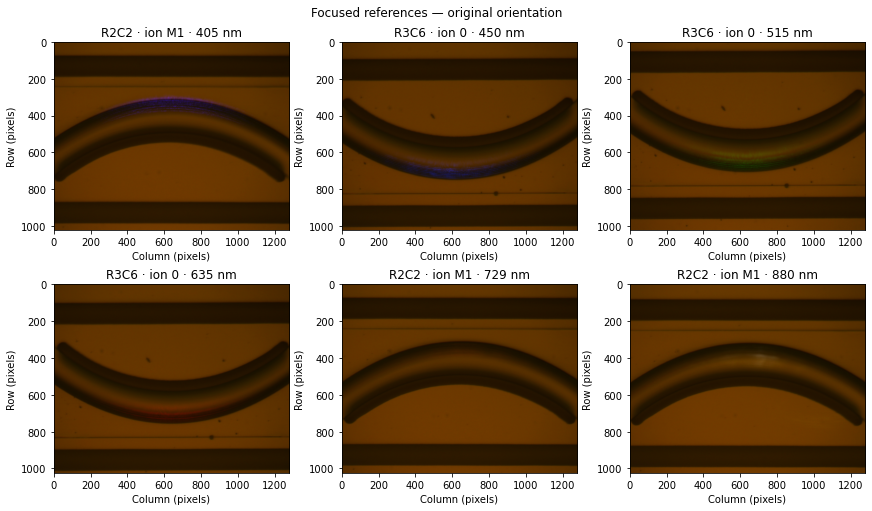

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for ax, wl in zip(axes.flat, WAVELENGTHS_NM):
    image = white_light[wl]
    scan = scans[wl]
    label = f"{scan.device_name} · ion {scan.ion_index}" if scan is not None else "Awaiting upload"
    ax.set_title(f"{label} · {wl} nm")
    if image is None:
        ax.text(0.5, 0.5, "Not measured yet", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
    else:
        ax.imshow(image, origin="upper", cmap="gray")
        ax.set(xlabel="Column (pixels)", ylabel="Row (pixels)")
fig.suptitle("Focused references — original orientation")
plt.show()

## Optional: load complete intensity stacks

Set `LOAD_FULL_STACKS = True` in Settings and rerun this cell to read every height plane into memory. For a single raw RGB frame at any acquisition index, use `scans[405].read_frame(frame_index=20)` instead. Loading a full stack leaves every source TIFF unchanged.

Scalar intensity follows the existing `Experimental_Import` convention: float32 **R + G + B**, avoiding uint8 overflow. No rotation, dark subtraction, exposure correction, or normalization has been applied. Corresponding heights and exposures are available as `scan.frames.height_um.to_numpy()` and `scan.frames.exposure_ms.to_numpy()` in the same order.

In [41]:
# Drop any earlier stacks before loading again.
intensity = dict.fromkeys(WAVELENGTHS_NM)
if LOAD_FULL_STACKS:
    for wl, scan in scans.items():
        if scan is not None:
            print(f"Loading {scan.device_name}, ion {scan.ion_index}, {wl} nm ({len(scan.frames)} frames)...", flush=True)
            intensity[wl] = scan.load_intensity()
            print(f"  shape={intensity[wl].shape}; {intensity[wl].nbytes / 2**20:.1f} MiB")
else:
    print("Full stacks not allocated. Logs, references, and sample frames are loaded.")

Loading R2C2, ion M1, 405 nm (150 frames)...
  shape=(150, 1024, 1280); 750.0 MiB
Loading R3C6, ion 0, 450 nm (150 frames)...
  shape=(150, 1024, 1280); 750.0 MiB
Loading R3C6, ion 0, 515 nm (150 frames)...
  shape=(150, 1024, 1280); 750.0 MiB
Loading R3C6, ion 0, 635 nm (150 frames)...
  shape=(150, 1024, 1280); 750.0 MiB
Loading R2C2, ion M1, 729 nm (150 frames)...
  shape=(150, 1024, 1280); 750.0 MiB
Loading R2C2, ion M1, 880 nm (150 frames)...
  shape=(150, 1024, 1280); 750.0 MiB


## Manual lens alignment — two points per wavelength

You choose **both points manually** on the original focused TIFF. Their joining line is rotated to horizontal. There is no automatic edge or corner detection. Click the same pair of physical lens features in each reference; click order does not matter. The midpoint of the two rotated points defines the lens origin, with x rightward and y upward.

The camera calibration below initially matches `Experimental_Import`: 5.3 µm camera pixels / 50× = **0.106 µm per image pixel**. This lateral calibration is separate from the 2:1 Z-stage ratio.

1. Run the alignment settings and `%matplotlib qt` cell. A window opens for each measured wavelength.
2. Click your two points with the left mouse button. A right click removes the most recent point before the second is selected. After the second point, the window closes and the next wavelength opens. Closing a window early cancels that wavelength without saving it; completed wavelengths are retained.
3. Run the inline preview cell and inspect the cyan line. Set `RESELECT_WAVELENGTHS = [405]` (or any desired list) and rerun alignment to replace a selection. Clear the list afterward.

Selections are saved independently as `ca_broadband_alignments_2/R2C2_ion_M1_405_nm.json` and `R3C6_ion_P1_450_nm.json`, etc. Later runs reuse them. Changed reference files or camera calibration require reselection. The rotation uses the existing importer's cropped nearest-neighbor convention, keeping frame dimensions and pixel values. Both clicked points and the rotation are saved. The gallery and alignment preview show the original camera orientation; the additional R3C6 vertical reflection is applied to selected height planes afterward.

In [42]:
PIXEL_SIZE_UM = 5.3
MAGNIFICATION = 50.0
RESELECT_WAVELENGTHS = []  # e.g. [405] or [405, 729, 880] to choose again.
ALIGNMENT_DIR = PROJECT_ROOT / "Gen_1_Paper" / "ca_broadband_alignments_2"

In [43]:
%matplotlib qt

alignments = align_scans_manual(
    scans, ALIGNMENT_DIR,
    reselect=RESELECT_WAVELENGTHS,
    pixel_size_um=PIXEL_SIZE_UM, magnification=MAGNIFICATION,
)

M1, 405 nm: reused manual rotation 0.0921 degrees
0, 450 nm: reused manual rotation -0.2759 degrees
0, 515 nm: reused manual rotation -0.8237 degrees
0, 635 nm: saved manual rotation -0.2746 degrees
M1, 729 nm: reused manual rotation -0.0920 degrees
M1, 880 nm: reused manual rotation 0.0000 degrees


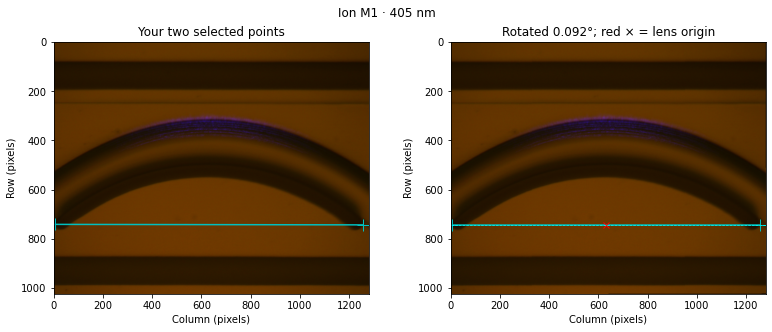

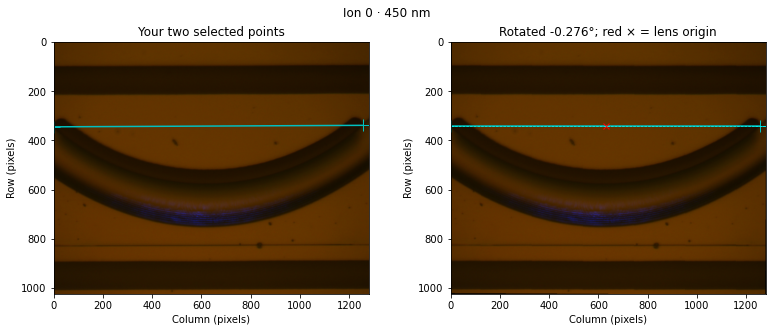

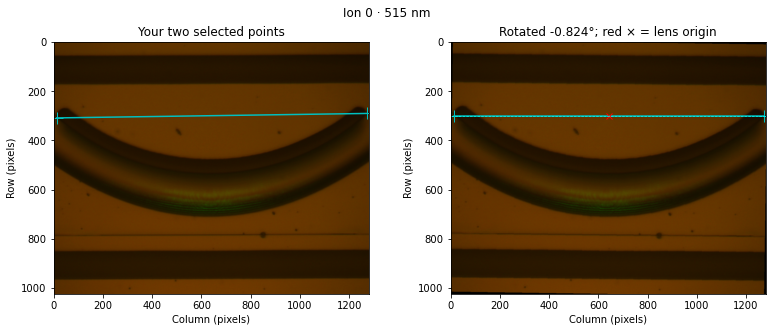

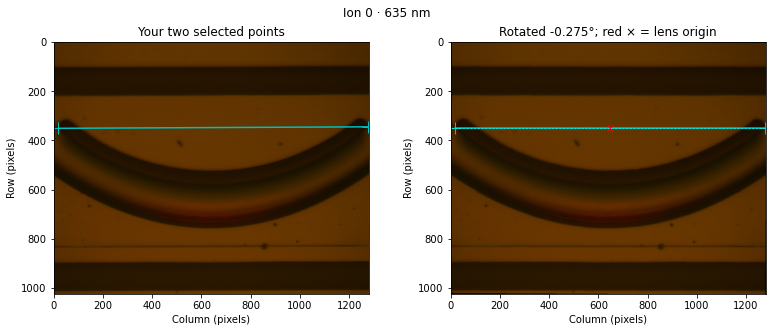

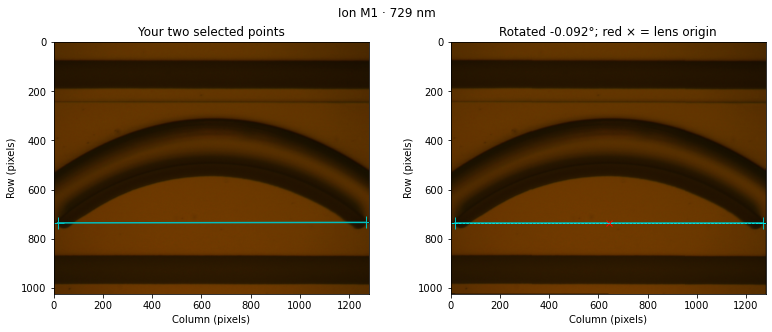

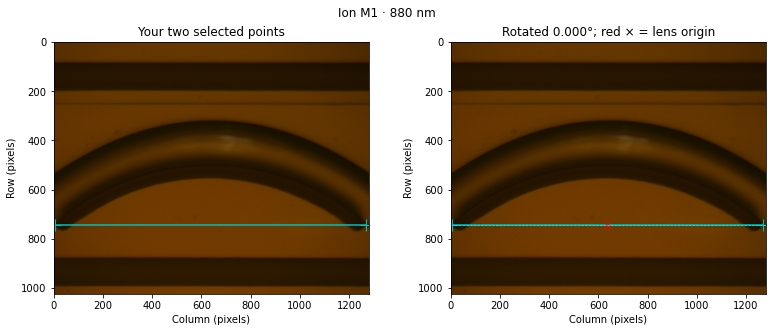

,wavelength_nm,device_name,ion_index,flip_vertical_for_plot,angle_deg,manual_points_px,lens_origin_px
0,405,R2C2,M1,False,0.092115,"[[3.650127726468696, 741.3919237571232], [1255...","[629.8103154963466, 742.4138920051839]"
1,450,R3C6,0,True,-0.275900,"[[1.6379445863626074, 344.99184515621926], [12...","[629.2494507215806, 341.92224436346373]"
2,515,R3C6,0,True,-0.823684,"[[11.698860286893165, 308.77254863430926], [12...","[644.5564536857692, 299.7685347629033]"
3,635,R3C6,0,True,-0.274578,"[[17.73540970721149, 351.0283945765376], [1277...","[648.3321289678051, 348.0505689828464]"
4,729,R2C2,M1,False,-0.091967,"[[15.723226567105371, 735.355374336805], [1269...","[642.1605677790957, 734.3538404223149]"
5,880,R2C2,M1,False,0.000000,"[[5.662310866574813, 743.4041068972293], [1267...","[636.4817252898408, 743.4041068972293]"


In [44]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"facecolor": "white", "edgecolor": "white", "transparent": False}

alignment_figures = preview_alignments(scans, alignments)
for figure in alignment_figures:
    display(figure)
    plt.close(figure)
display(pd.DataFrame([
    {"wavelength_nm": wl, "device_name": scans[wl].device_name,
     "ion_index": scans[wl].ion_index, "flip_vertical_for_plot": scans[wl].flip_vertical,
     "angle_deg": a["angle_deg"],
     "manual_points_px": a["points_px"], "lens_origin_px": a["origin_px"]}
    for wl, a in alignments.items() if a is not None
]))

## Choose the height and plot window

Choose a common `HEIGHT_UM` above the focused surface, or supply an entry in `HEIGHT_BY_WAVELENGTH_UM` to choose a different height for a wavelength. The nearest measured plane is selected **without interpolation**, within `MAX_HEIGHT_ERROR_UM`. The table and panel titles report the actual sampled height. A requested height beyond a scan's coverage raises a clear error instead of silently picking a distant plane. Use the discovery inventory to check the current height range for each device and wavelength.

The plot uses a ±30 µm window centered separately on each beam's brightest pixel by default, matching the reference figure's layout. Lens-relative coordinates are preserved in the result. To exclude another bright feature or a hot pixel, give `PEAK_ROI_UM[wl] = (xmin, xmax, ymin, ymax)` in aligned lens coordinates. To set the center directly, use `CENTER_UM[wl] = (x, y)` instead. The alignment previews show the lens origin in red. For R3C6, `PEAK_ROI_UM` and `CENTER_UM` use the vertically reflected lens coordinates (y changes sign relative to the unflipped preview). The mounting reflection affects image y only; it does not change the physical scan height.

Each panel is normalized to its **own displayed maximum**, giving a 0–1 scale. No automatic background subtraction or exposure correction is applied; the figure compares normalized shapes. Optional `BACKGROUND_COUNTS[wl]` subtracts a user-specified scalar in raw R+G+B units before clipping to zero. Exposure times, subtraction, chosen centers, and normalization peaks are recorded in the export.

Use `GLOBAL_X_SHIFT_UM` and `GLOBAL_Y_SHIFT_UM` for a common translation of every image panel, after each beam is centered. Positive X moves the beams right, positive Y moves them up; for example `(5, -3)` moves every beam 5 µm right and 3 µm down inside the fixed ±30 µm axes. Change these values in the settings cell, then rerun the plot cell. Shifts are recorded in the export metadata and plotted x/y arrays.

In [56]:
HEIGHT_UM =75.0  # Physical height above focus; change this and rerun the next cell.
HEIGHT_BY_WAVELENGTH_UM = {}  # e.g. {405: 70.0}; others use HEIGHT_UM.
MAX_HEIGHT_ERROR_UM = 0.6
HALF_WIDTH_UM = 30.0
GLOBAL_X_SHIFT_UM = 0.0  # Positive moves every beam right; negative moves left.
GLOBAL_Y_SHIFT_UM = 0.0  # Positive moves every beam up; negative moves down.
SHOW_HEIGHTS = True
FONT_SIZE = 13

PEAK_ROI_UM = dict.fromkeys(WAVELENGTHS_NM)  # Optional lens-relative search rectangle.
CENTER_UM = dict.fromkeys(WAVELENGTHS_NM)    # Optional lens-relative (x, y) center.
BACKGROUND_COUNTS = {wl: 0.0 for wl in WAVELENGTHS_NM}

,device_name,ion_index,wavelength_nm,flip_vertical,requested_height_um,selected_height_um,frame_index,exposure_ms,center_um,normalization_peak_counts
0,R2C2,M1,405,False,75.0,74.9375,74,2.614148,"[4.154106557387264, 6.933872552549496]",225.0
1,R3C6,0,450,True,75.0,74.9375,74,1.310166,"[-0.6624417764875452, 9.124242097472845]",224.0
2,R3C6,0,515,True,75.0,74.9380,74,2.253711,"[-0.27098409069153057, 9.88253531513225]",193.0
3,R3C6,0,635,True,75.0,74.9380,74,2.587719,"[-0.6712056705873456, 9.21663968781828]",200.0
4,R2C2,M1,729,False,75.0,74.9375,74,11.422065,"[2.5269798154158574, 15.301507084765376]",240.0
5,R2C2,M1,880,False,75.0,74.9340,74,7.772155,"[4.294937119276873, 12.232835331106308]",539.0


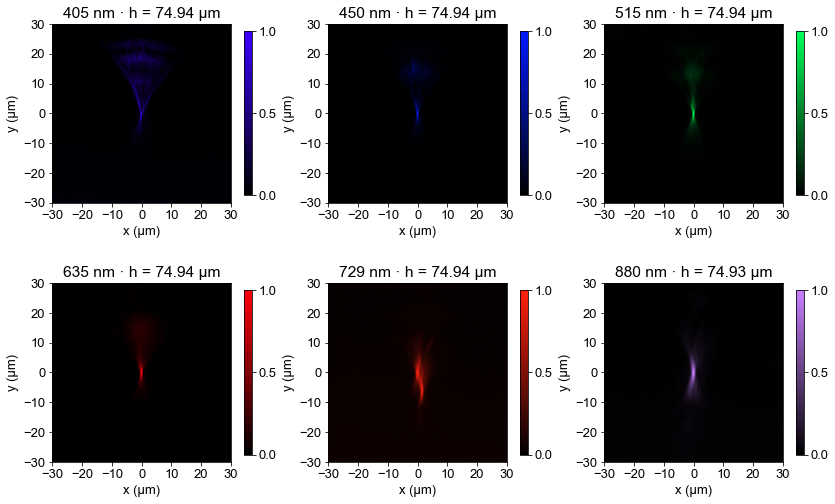

In [57]:
# Display with an opaque white canvas, including in a dark notebook theme.
%config InlineBackend.print_figure_kwargs = {"facecolor": "white", "edgecolor": "white", "transparent": False}

from importlib import reload
import Analysis.ca_3d_plotting as ca_plotting
plot_publication_grid = reload(ca_plotting).plot_publication_grid

# Always read the selected source frame, avoiding a stale stack if ION_INDEX changed.
planes = dict.fromkeys(WAVELENGTHS_NM)
for wl, scan in scans.items():
    if scan is None:
        continue
    if alignments.get(wl) is None:
        raise RuntimeError(f"Complete manual alignment for {wl} nm first.")
    planes[wl] = select_height_plane(
        scan, alignments[wl], HEIGHT_BY_WAVELENGTH_UM.get(wl, HEIGHT_UM),
        max_height_error_um=MAX_HEIGHT_ERROR_UM,
        center_um=CENTER_UM[wl], peak_roi_um=PEAK_ROI_UM[wl],
        background_counts=BACKGROUND_COUNTS[wl],
    )

if "publication_figure" in globals():
    plt.close(publication_figure)
publication_figure, publication_metadata, publication_arrays = plot_publication_grid(
    planes, half_width_um=HALF_WIDTH_UM, font_size=FONT_SIZE, show_heights=SHOW_HEIGHTS,
    x_shift_um=GLOBAL_X_SHIFT_UM, y_shift_um=GLOBAL_Y_SHIFT_UM,
)
display(publication_metadata[[
    "device_name", "ion_index", "wavelength_nm", "flip_vertical",
    "requested_height_um", "selected_height_um",
    "frame_index", "exposure_ms", "center_um", "normalization_peak_counts",
]])
display(publication_figure)
plt.close(publication_figure)

## Gaussian beam size versus wavelength

Run the height-plane plot above first. This analysis uses those same selected heights, manual rotations, R3C6 vertical reflections, and scalar background settings. For each available wavelength, `Experimental_Analysis.from_image` finds the **maximum pixel of the full aligned image** and extracts two single-pixel cuts through it: **axial = x (maximum's row)** and **radial = y (maximum's column)**. Display translations and the six-tile crop do not affect the fit.

Each cut is fit within `BEAM_FIT_HALF_WIDTH_UM` of its peak to **I(u) = B + A exp[−2(u−u₀)²/w²]**, including a fitted nonnegative constant background. The **1/e² intensity radius is w**. The table also reports **FWHM = √(2 ln 2) × w**. Set `BEAM_SIZE_QUANTITY = "fwhm"` to reproduce the width convention used by panel (b) in `paper_figures.ipynb`; `"radius"` plots beam radii. Colors match the six image tiles, with circles for radial and diamonds for axial.

Inspect the profile overlays and R² values before using a width. Failed fits have explicit status/error entries and no plotted point; `check fit window` means a fitted half-maximum falls outside the available fitting interval. Missing wavelengths remain absent. Fitted widths are point estimates; no averaging, smoothing, or pixel interpolation is added.


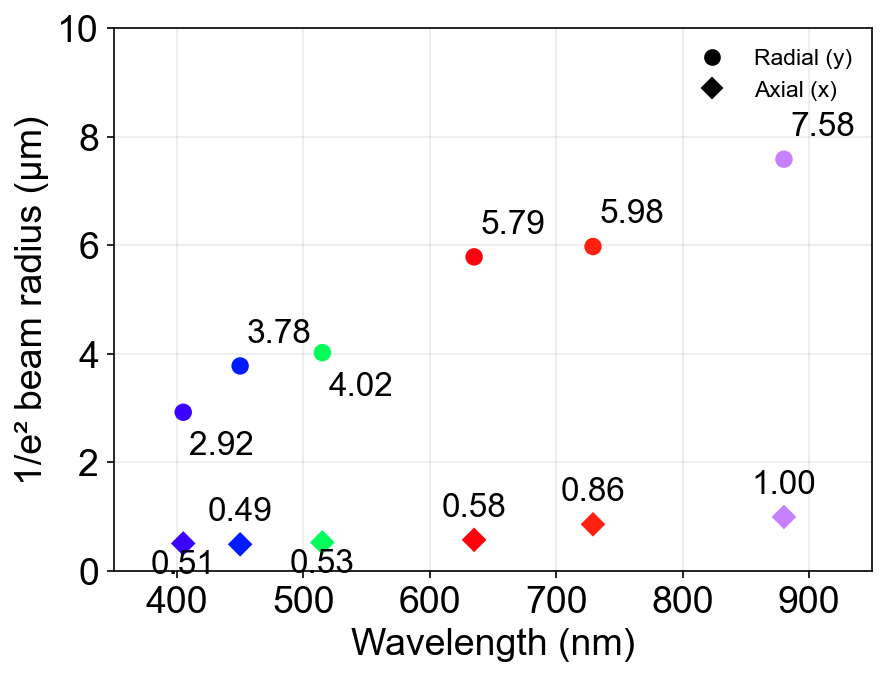

,wavelength_nm,device_name,ion_index,selected_height_um,requested_height_um,frame_index,exposure_ms,flip_vertical,source_path,fit_half_width_um,...,peak_y_um,peak_counts,axial_r_squared,axial_background_counts,axial_half_max_covered,radial_r_squared,radial_background_counts,radial_half_max_covered,status,fit_error
0,405,R2C2,M1,79.9330,80.0,79,1.760571,False,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,30.0,...,0.000,230.0,0.953849,1.098001,True,0.785878,19.222866,True,ok,
1,450,R3C6,0,79.9295,80.0,79,1.860661,True,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,30.0,...,0.212,209.0,0.998703,0.063897,True,0.811193,13.658815,True,ok,
2,515,R3C6,0,79.9370,80.0,79,2.781714,True,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,30.0,...,0.000,181.0,0.997079,0.449290,True,0.786396,14.379511,True,ok,
3,635,R3C6,0,79.9335,80.0,79,2.529240,True,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,30.0,...,0.106,182.0,0.997151,0.340264,True,0.891361,9.654249,True,ok,
4,729,R2C2,M1,79.9330,80.0,79,6.560954,False,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,30.0,...,0.000,239.0,0.959206,6.269779,True,0.988505,11.560813,True,ok,
5,880,R2C2,M1,79.9295,80.0,79,15.014058,False,/Users/yiyangzhi/Library/CloudStorage/GoogleDr...,30.0,...,0.000,547.0,0.978205,13.616397,True,0.933122,32.995494,True,ok,


In [55]:
from importlib import reload
import Analysis.Experimental_Analysis as experimental_analysis
import Analysis.ca_3d_plotting as ca_plotting
reload(experimental_analysis)
reload(ca_plotting)

BEAM_FIT_HALF_WIDTH_UM = 30.0  # Fit ± this distance around each slice maximum.
BEAM_SIZE_QUANTITY = "radius"  # "radius" (1/e²) or "fwhm" (paper panel b).

if "planes" not in globals():
    raise RuntimeError("Run the height-plane plot cell above first.")
beam_size_table, beam_profile_fits = ca_plotting.fit_beam_sizes(
    planes, half_width_um=BEAM_FIT_HALF_WIDTH_UM,
)
if "beam_size_figure" in globals():
    plt.close(beam_size_figure)
beam_size_figure = ca_plotting.plot_beam_sizes(
    beam_size_table, quantity=BEAM_SIZE_QUANTITY,
)
display(beam_size_figure)
plt.close(beam_size_figure)
display(beam_size_table)


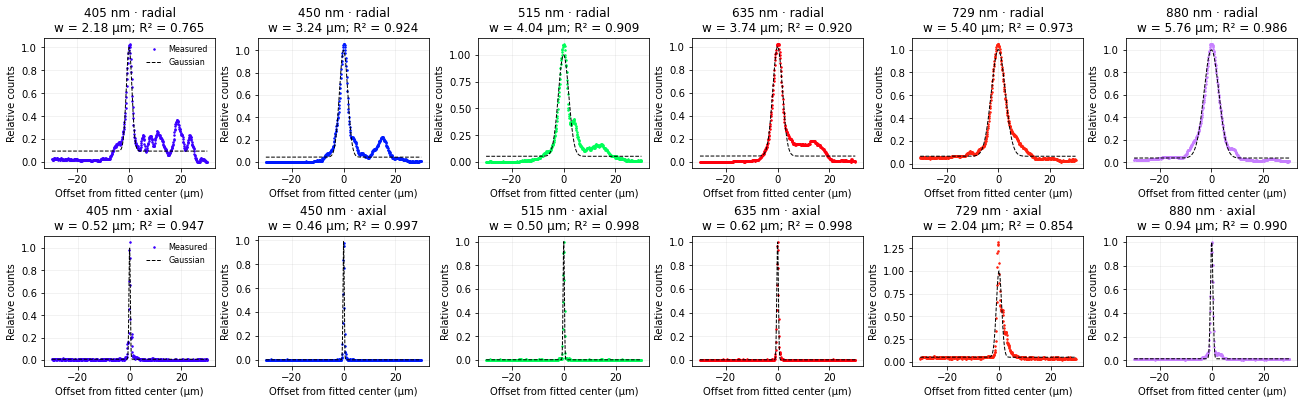

In [48]:
# Inspect both measured profiles and Gaussian fits for every wavelength.
if "beam_profile_figure" in globals():
    plt.close(beam_profile_figure)
beam_profile_figure = ca_plotting.plot_beam_profile_fits(beam_profile_fits)
display(beam_profile_figure)
plt.close(beam_profile_figure)

# Optional export: uncomment after checking the fits.
# BEAM_OUTPUT_DIR = PROJECT_ROOT / "Gen_1_Paper" / "ca_broadband_results"
# BEAM_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# BEAM_STEM = f"beam_sizes_ca_{ION_INDEX}_ba_{BARIUM_ION_INDEX}_height_{HEIGHT_UM:g}um"
# beam_size_table.to_csv(BEAM_OUTPUT_DIR / f"{BEAM_STEM}.csv", index=False)
# for extension in ("png", "pdf", "svg"):
#     beam_size_figure.savefig(BEAM_OUTPUT_DIR / f"{BEAM_STEM}.{extension}",
#                             dpi=600, bbox_inches="tight", facecolor="white")


## Export publication figure and plotted data

Run this cell when the alignment and height look right. Exports include a 600 dpi PNG, vector PDF/SVG with raster image panels, an NPZ with the exact cropped raw/normalized intensity and x/y axes, and a JSON with acquisition and processing metadata including all manual alignment points, source device, source ion label, and the vertical-reflection flag. Missing wavelengths remain labeled placeholders. Reusing the same `EXPORT_STEM` replaces that export; change it to keep another version.

In [49]:
# OUTPUT_DIR = PROJECT_ROOT / "Gen_1_Paper" / "ca_broadband_results"
# EXPORT_STEM = f"broadband_ca_{ION_INDEX}_ba_{BARIUM_ION_INDEX}_height_{HEIGHT_UM:g}um"
# exported_paths = export_publication(
#     publication_figure, publication_metadata, publication_arrays, OUTPUT_DIR, EXPORT_STEM,
# )
# for path in exported_paths:
#     print(path.relative_to(PROJECT_ROOT))

## Peak count rate versus height

For every measured frame, calculate

`peak_count_rate_per_s = max_over_pixels(R + G + B) / (exposure_ms / 1000)`

This is the brightest **single-pixel camera count rate**, in counts/s. Use the original full frame so rotation or cropping cannot discard a maximum; no manual alignment is needed for this calculation. A vertical flip preserves the maximum, so this calculation also uses the original R3C6 frames; peak row/column coordinates remain raw camera coordinates. There is no smoothing, background subtraction, or normalization to a curve's own maximum. Heights use each wavelength's focused zero and the 2:1 stage ratio, as above.

Each wavelength retains its own measured height range and vertical count-rate scale. These camera counts are exposure-normalized, but have not been corrected for wavelength-dependent camera response or input laser power. A circle marks the largest measured rate in each curve; the table lists that plane's actual height, frame index, exposure, and peak counts.

Run the calculation cell once after importing `scans`; it reads one TIFF at a time. Then rerun just the plot cell to change between `"linear"` and `"log"` display. The DataFrames in `peak_rate_tables` preserve all per-frame values and peak pixel coordinates.

In [50]:
from importlib import reload
import Analysis.ca_3d_import as ca_import
import Analysis.ca_3d_plotting as ca_plotting
peak_count_rate_vs_height = reload(ca_import).peak_count_rate_vs_height
plot_peak_count_rates = reload(ca_plotting).plot_peak_count_rates

peak_rate_tables = dict.fromkeys(WAVELENGTHS_NM)
for wl, scan in scans.items():
    if scan is None:
        continue
    print(f"{scan.device_name}, ion {scan.ion_index}, {wl} nm: calculating peak rates for {len(scan.frames)} frames...", flush=True)
    peak_rate_tables[wl] = peak_count_rate_vs_height(scan)
peak_rate_data = pd.concat(
    [table for table in peak_rate_tables.values() if table is not None], ignore_index=True,
)
print(f"Calculated {len(peak_rate_data)} frame rates.")

R2C2, ion M1, 405 nm: calculating peak rates for 150 frames...
R3C6, ion 0, 450 nm: calculating peak rates for 150 frames...
R3C6, ion 0, 515 nm: calculating peak rates for 150 frames...
R3C6, ion 0, 635 nm: calculating peak rates for 150 frames...
R2C2, ion M1, 729 nm: calculating peak rates for 150 frames...
R2C2, ion M1, 880 nm: calculating peak rates for 150 frames...
Calculated 900 frame rates.


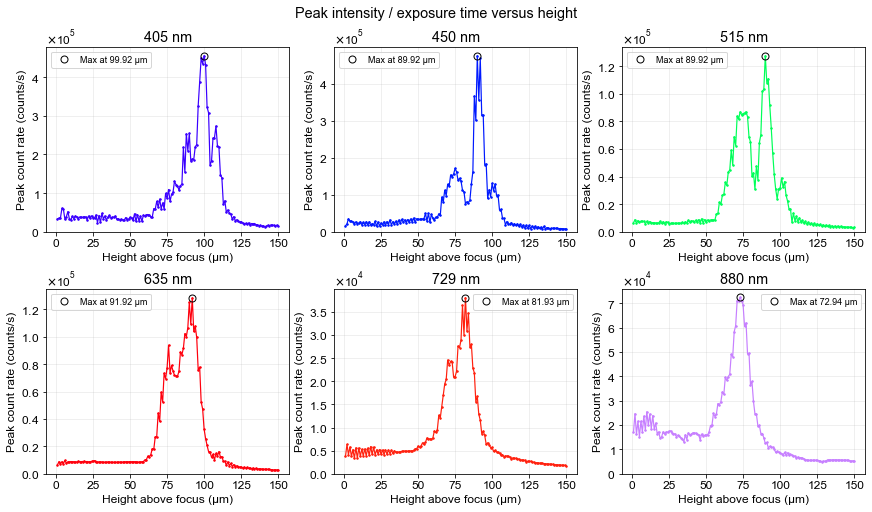

,device_name,ion_index,wavelength_nm,height_um,image_index,exposure_ms,peak_counts,peak_count_rate_per_s
0,R2C2,M1,405,99.9195,99,0.483018,220.0,455469.149745
1,R3C6,0,450,89.9210,89,0.454903,216.0,474826.205036
2,R3C6,0,515,89.9245,89,1.473797,188.0,127561.694024
3,R3C6,0,635,91.9190,91,1.517094,195.0,128535.211276
4,R2C2,M1,729,81.9315,81,6.429937,245.0,38103.017053
5,R2C2,M1,880,72.9355,72,7.772155,563.0,72438.084212


In [51]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"facecolor": "white", "edgecolor": "white", "transparent": False}

RATE_Y_SCALE = "linear"  # "linear" or "log"; rates remain in counts/s.
if "peak_rate_figure" in globals():
    plt.close(peak_rate_figure)
peak_rate_figure, peak_rate_maxima = plot_peak_count_rates(
    peak_rate_tables, y_scale=RATE_Y_SCALE,
)
display(peak_rate_figure)
plt.close(peak_rate_figure)
display(peak_rate_maxima[[
    "device_name", "ion_index", "wavelength_nm", "height_um", "image_index",
    "exposure_ms", "peak_counts", "peak_count_rate_per_s",
]])

In [52]:
# Optional: export the plotted rates and their figure.
# RATE_OUTPUT_DIR = PROJECT_ROOT / "Gen_1_Paper" / "ca_broadband_results"
# RATE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# RATE_STEM = f"broadband_peak_count_rate_ca_{ION_INDEX}_ba_{BARIUM_ION_INDEX}"
# peak_rate_data.to_csv(RATE_OUTPUT_DIR / f"{RATE_STEM}.csv", index=False)
# for extension in ("png", "pdf", "svg"):
#     peak_rate_figure.savefig(
#         RATE_OUTPUT_DIR / f"{RATE_STEM}.{extension}", dpi=600,
#         bbox_inches="tight", facecolor="white", transparent=False,
#     )